Cohort: A group of customers who started their journey during the same time period.

In [1]:
import pandas as pd
import numpy as np

from google.colab import drive
drive.mount('/content/drive')

FILE_PATH = "/content/drive/MyDrive/Revenue_Intelligence_Project/Data/customer_analytics.csv"

Mounted at /content/drive


In [2]:
df = pd.read_csv(FILE_PATH)

df["InvoiceDate"] = pd.to_datetime(
    df["InvoiceDate"]
)

print(df.shape)

(779495, 9)


In [3]:
df["InvoiceMonth"] = (
    df["InvoiceDate"]
    .dt.to_period("M")
)

In [4]:
df["CohortMonth"] = (
    df.groupby("Customer ID")["InvoiceMonth"]
      .transform("min")
)

In [5]:
df[
    [
        "Customer ID",
        "InvoiceMonth",
        "CohortMonth"
    ]
].head()

,Customer ID,InvoiceMonth,CohortMonth
0,13085.0,2009-12,2009-12
1,13085.0,2009-12,2009-12
2,13085.0,2009-12,2009-12
3,13085.0,2009-12,2009-12
4,13085.0,2009-12,2009-12


Cohort Index

In [6]:
invoice_year = df["InvoiceMonth"].dt.year
invoice_month = df["InvoiceMonth"].dt.month

cohort_year = df["CohortMonth"].dt.year
cohort_month = df["CohortMonth"].dt.month

year_diff = invoice_year - cohort_year
month_diff = invoice_month - cohort_month

df["CohortIndex"] = (
    year_diff * 12
    + month_diff
    + 1
)

In [7]:
df[
    [
        "Customer ID",
        "CohortMonth",
        "InvoiceMonth",
        "CohortIndex"
    ]
].head(20)

,Customer ID,CohortMonth,InvoiceMonth,CohortIndex
0,13085.0,2009-12,2009-12,1
1,13085.0,2009-12,2009-12,1
2,13085.0,2009-12,2009-12,1
3,13085.0,2009-12,2009-12,1
4,13085.0,2009-12,2009-12,1
5,13085.0,2009-12,2009-12,1
6,13085.0,2009-12,2009-12,1
7,13085.0,2009-12,2009-12,1
8,13085.0,2009-12,2009-12,1
9,13085.0,2009-12,2009-12,1


In [8]:
cohort_data = (
    df.groupby(
        ["CohortMonth", "CohortIndex"]
    )["Customer ID"]
    .nunique()
    .reset_index()
)

cohort_data.head(15)

,CohortMonth,CohortIndex,Customer ID
0,2009-12,1,955
1,2009-12,2,337
2,2009-12,3,319
3,2009-12,4,406
4,2009-12,5,363
5,2009-12,6,343
6,2009-12,7,360
7,2009-12,8,327
8,2009-12,9,321
9,2009-12,10,346


In [9]:
cohort_counts = cohort_data.pivot(
    index="CohortMonth",
    columns="CohortIndex",
    values="Customer ID"
)

cohort_counts.head()

CohortIndex,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,955.0,337.0,319.0,406.0,363.0,343.0,360.0,327.0,321.0,346.0,...,289.0,251.0,289.0,270.0,248.0,244.0,301.0,291.0,389.0,188.0
2010-01,383.0,79.0,119.0,117.0,101.0,115.0,99.0,88.0,107.0,122.0,...,58.0,90.0,76.0,71.0,75.0,93.0,74.0,94.0,22.0,NaN
2010-02,376.0,89.0,84.0,109.0,92.0,75.0,72.0,107.0,95.0,103.0,...,75.0,60.0,61.0,54.0,86.0,86.0,61.0,22.0,NaN,NaN
2010-03,443.0,84.0,102.0,107.0,103.0,90.0,109.0,134.0,122.0,48.0,...,75.0,77.0,69.0,78.0,89.0,94.0,35.0,NaN,NaN,NaN
2010-04,294.0,57.0,57.0,48.0,54.0,66.0,81.0,77.0,31.0,32.0,...,46.0,41.0,44.0,53.0,66.0,17.0,NaN,NaN,NaN,NaN


In [10]:
cohort_size = cohort_counts.iloc[:, 0]

retention = cohort_counts.divide(
    cohort_size,
    axis=0
)

retention.head()

CohortIndex,1,2,3,4,5,6,7,8,9,10,...,16,17,18,19,20,21,22,23,24,25
CohortMonth,,,,,,,,,,,,,,,,,,,,,
2009-12,1.0,0.352880,0.334031,0.425131,0.380105,0.359162,0.376963,0.342408,0.336126,0.362304,...,0.302618,0.262827,0.302618,0.282723,0.259686,0.255497,0.315183,0.304712,0.407330,0.196859
2010-01,1.0,0.206266,0.310705,0.305483,0.263708,0.300261,0.258486,0.229765,0.279373,0.318538,...,0.151436,0.234987,0.198433,0.185379,0.195822,0.242820,0.193211,0.245431,0.057441,NaN
2010-02,1.0,0.236702,0.223404,0.289894,0.244681,0.199468,0.191489,0.284574,0.252660,0.273936,...,0.199468,0.159574,0.162234,0.143617,0.228723,0.228723,0.162234,0.058511,NaN,NaN
2010-03,1.0,0.189616,0.230248,0.241535,0.232506,0.203160,0.246050,0.302483,0.275395,0.108352,...,0.169300,0.173815,0.155756,0.176072,0.200903,0.212190,0.079007,NaN,NaN,NaN
2010-04,1.0,0.193878,0.193878,0.163265,0.183673,0.224490,0.275510,0.261905,0.105442,0.108844,...,0.156463,0.139456,0.149660,0.180272,0.224490,0.057823,NaN,NaN,NaN,NaN


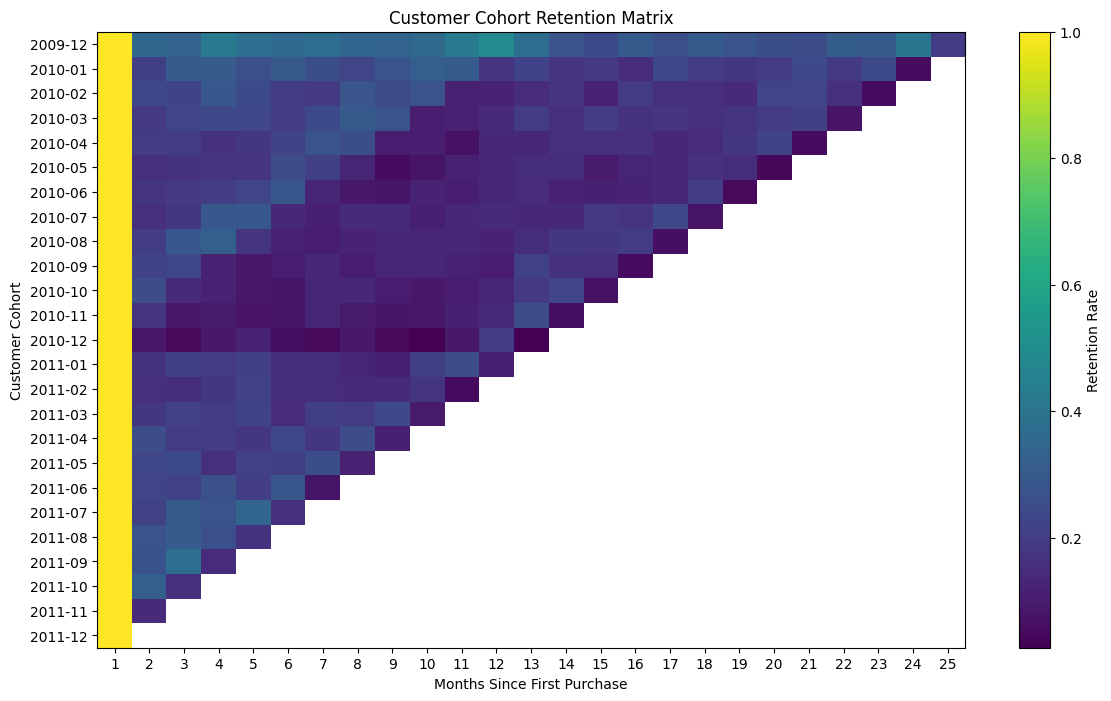

In [11]:
import matplotlib.pyplot as plt

plt.figure(figsize=(14,8))

plt.imshow(
    retention,
    aspect="auto"
)

plt.colorbar(label="Retention Rate")

plt.title("Customer Cohort Retention Matrix")

plt.xlabel("Months Since First Purchase")

plt.ylabel("Customer Cohort")

plt.xticks(
    range(len(retention.columns)),
    retention.columns
)

plt.yticks(
    range(len(retention.index)),
    retention.index.astype(str)
)

plt.show()